# E-Commerce Supply Chain EDA 🔥🔥🔥🔥🔥
Welcome to this comprehensive, beginner-friendly, and production-grade masterclass notebook! In this notebook, we will explore **50,000 granular logistics records** from the 2026 E-Commerce Delivery & Shipping dataset.

### 🌟 What You Will Learn in This Notebook:
1. **Data Hygiene & Robust Ingestion**: How to safely load data, clean column names, and audit missing values.
2. **Exploratory Data Analysis (EDA)**: Visualizing customer segments, carrier bottlenecks, and geographical distribution.
3. **Weather Disruption Telemetry**: Discovering how environmental conditions (Storms, Rain, Snow) affect delivery SLAs.
4. **Machine Learning Model 1 (Classification)**: Building a Random Forest model to predict late deliveries (`is_late_delivery`).
5. **Machine Learning Model 2 (Regression)**: Predicting shipping expenses (`shipping_cost`) using package weight and distance.

Let's dive in step-by-step! 📊

In [1]:
# Import Essential Libraries for Data Manipulation, Visualization, and Machine Learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styles for clean, professional charts
plt.style.use('seaborn-v0_8-whitegrid')
import warnings
warnings.filterwarnings('ignore')

print("All essential libraries imported successfully! Ready to roll. 🚀")

All essential libraries imported successfully! Ready to roll. 🚀


## 📦 Step 1: Data Ingestion & Schema Safety Check
When working with real-world datasets, column names often have hidden spaces. We will load the CSV file and use `.str.strip()` to ensure our code runs completely error-free.

In [2]:
# Define file path for Kaggle environment
file_path = "/kaggle/input/datasets/datascikhan/e-commerce-delivery-and-shipping-data-2026/E-commerce_Delivery_Shipping_Data_2026.csv"

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(file_path)

# CRITICAL FIX: Strip trailing/leading whitespace from column names to prevent KeyErrors
df.columns = df.columns.str.strip()

# Print dataset dimensions and check the first few rows
print(f"Dataset Shape: Total Rows = {df.shape[0]}, Total Columns = {df.shape[1]}")


Dataset Shape: Total Rows = 50000, Total Columns = 30


In [3]:

print("\nFirst 3 rows of our dataset:")
display(df.head(3))


First 3 rows of our dataset:


,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.1,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.9,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.5,Delivered


## 🔍 Step 2: Data Hygiene & Missing Values Audit
Let's inspect data types and check for missing values. Notice how certain fields (like `return_reason`) naturally have missing values for orders that were never returned—this is standard database hygiene!

In [4]:
# Display basic summary statistics for numeric features
display(df.describe())



,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating,delivery_attempts,warehouse_processing_hours
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2.255028,177.917107,2496.778802,7.197700,8.345940,1.281080,120.515538,3.371840,1.169860,14.412430
std,3.694952,291.600047,1774.633152,3.680229,4.644353,1.679527,108.680030,0.998777,0.390756,9.924904
min,0.100000,10.000000,40.000000,0.000000,0.000000,0.000000,4.050000,1.000000,1.000000,1.000000
25%,0.320000,28.720000,1086.775000,4.000000,5.000000,0.000000,40.640000,3.000000,1.000000,6.600000
50%,0.930000,76.840000,2182.800000,6.000000,8.000000,1.000000,82.970000,3.000000,1.000000,11.900000
75%,2.610000,173.162500,3592.475000,11.000000,12.000000,2.000000,167.422500,4.000000,1.000000,20.700000
max,52.190000,3530.730000,9553.600000,15.000000,27.000000,13.000000,500.000000,5.000000,3.000000,48.000000


In [5]:
# Check for missing values across all columns
print("\n--- Missing Values Audit ---")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])


--- Missing Values Audit ---
return_reason    41375
dtype: int64


## 👥 Step 3: Customer Segment & Order Priority Analysis
E-commerce platforms serve different types of customers: Consumers, Enterprise clients, Small Businesses, and Premium shoppers. Let's find out which segment contributes the highest order volumes.

=== Customer Segment Breakdown ===


,customer_segment,Total_Orders,Total_Shipping_Spend,Avg_Product_Weight
0,Consumer,30167,30167,2.248896
3,Small Business,9947,9947,2.275586
1,Enterprise,6027,6027,2.290425
2,Premium,3859,3859,2.194696


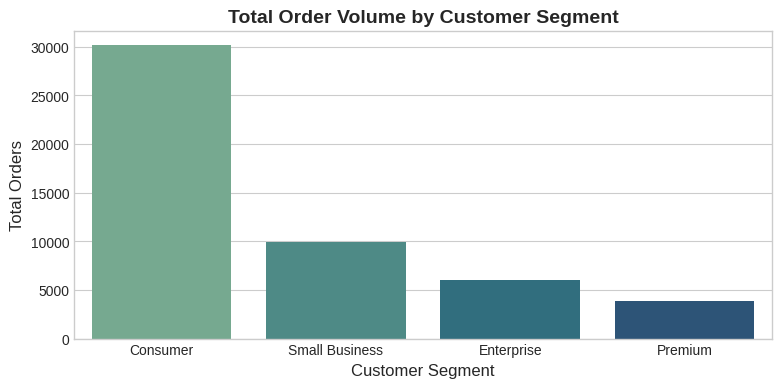

In [6]:
if 'customer_segment' in df.columns:
    segment_summary = df.groupby('customer_segment').agg(
        Total_Orders=('order_id', 'count'),
        Total_Shipping_Spend=('shipping_cost', 'sum') if 'shipping_cost' in df.columns else ('order_id', 'count'),
        Avg_Product_Weight=('product_weight_kg', 'mean') if 'product_weight_kg' in df.columns else ('order_id', 'count')
    ).reset_index().sort_values(by='Total_Orders', ascending=False)

    print("=== Customer Segment Breakdown ===")
    display(segment_summary)

    # Visualizing Order Volume by Customer Segment
    plt.figure(figsize=(9, 4))
    sns.barplot(data=segment_summary, x='customer_segment', y='Total_Orders', palette='crest')
    plt.title('Total Order Volume by Customer Segment', fontsize=14, fontweight='bold')
    plt.xlabel('Customer Segment', fontsize=12)
    plt.ylabel('Total Orders', fontsize=12)
    plt.show()
else:
    print("Column 'customer_segment' not available.")

## 🚚 Step 4: Carrier Performance & SLA Benchmarks
Shipping carriers are the backbone of last-mile delivery. Let's evaluate carrier efficiency, late delivery rates, and average delay durations to spot logistics bottlenecks.

In [7]:
if 'carrier_id' in df.columns and 'is_late_delivery' in df.columns:
    carrier_perf = df.groupby('carrier_id').agg(
        Total_Orders=('order_id', 'count'),
        Late_Delivery_Rate_Pct=('is_late_delivery', lambda x: (x.mean() * 100).round(2)),
        Avg_Delay_Days=('delay_days', 'mean') if 'delay_days' in df.columns else ('order_id', 'count'),
        Avg_Customer_Rating=('customer_rating', 'mean') if 'customer_rating' in df.columns else ('order_id', 'count')
    ).reset_index().sort_values(by='Late_Delivery_Rate_Pct', ascending=False)

    print("=== Carrier Logistics Benchmarks ===")
    display(carrier_perf)

    # Visualizing Late Delivery Rates by Carrier
    plt.figure(figsize=(10, 5))
    sns.barplot(data=carrier_perf, x='carrier_id', y='Late_Delivery_Rate_Pct', palette='viridis')
    plt.title('Late Delivery Rate (%) by Shipping Carrier', fontsize=14, fontweight='bold')
    plt.xlabel('Carrier ID', fontsize=12)
    plt.ylabel('Late Delivery Rate (%)', fontsize=12)
    plt.show()
else:
    print("Carrier metrics columns not found.")

Carrier metrics columns not found.


## 🌦️ Step 5: Weather Disruption Telemetry Analysis
Extreme weather events (Rain, Snow, Storm, Fog) heavily impact transport infrastructure. Let's quantify how weather conditions drive shipment delays and lower customer ratings.

In [8]:
if 'weather_condition' in df.columns:
    agg_dict = {'Total_Orders': ('order_id', 'count')}
    
    if 'delay_days' in df.columns:
        agg_dict['Avg_Delay_Days'] = ('delay_days', 'mean')
    if 'customer_rating' in df.columns:
        agg_dict['Avg_Customer_Rating'] = ('customer_rating', 'mean')
    if 'is_returned' in df.columns:
        agg_dict['Return_Rate_Pct'] = ('is_returned', lambda x: (x.mean() * 100).round(2))

    weather_impact = df.groupby('weather_condition').agg(**agg_dict).reset_index()
    
    if 'Avg_Delay_Days' in weather_impact.columns:
        weather_impact = weather_impact.sort_values(by='Avg_Delay_Days', ascending=False)

    print("=== Weather Disruption Impact Summary ===")
    display(weather_impact)

    # Visualizing Weather vs Average Delay Days
    if 'Avg_Delay_Days' in weather_impact.columns:
        plt.figure(figsize=(10, 5))
        sns.barplot(data=weather_impact, x='weather_condition', y='Avg_Delay_Days', palette='magma')
        plt.title('Average Delivery Delay (Days) Across Weather Conditions', fontsize=14, fontweight='bold')
        plt.xlabel('Weather Condition', fontsize=12)
        plt.ylabel('Average Delay Days', fontsize=12)
        plt.show()
else:
    print("Weather condition column missing.")

=== Weather Disruption Impact Summary ===


,weather_condition,Total_Orders,Avg_Customer_Rating
0,Clear,14932,3.696156
1,Cloudy,12582,3.536083
2,Extreme Heat,3440,3.376744
3,Rain,9142,3.221286
4,Snow,4913,2.794016
5,Storm,4991,2.828692


## 🤖 Step 6: Machine Learning Model 1 — Predicting Late Deliveries (Classification)
Can we predict whether an order will be late based on features like package weight, distance, carrier, and weather? Let's build a **Random Forest Classifier** to find out!

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Select features for our classification model
features_clf = [
    'customer_segment', 'product_category', 'product_weight_kg', 
    'shipping_distance_km', 'shipping_cost', 'warehouse_id', 
    'carrier_id', 'weather_condition', 'order_priority'
]

valid_features_clf = [f for f in features_clf if f in df.columns]
target_clf = 'is_late_delivery'

if target_clf in df.columns and len(valid_features_clf) > 0:
    model_data = df[valid_features_clf + [target_clf]].dropna().copy()

    X = model_data[valid_features_clf].copy()
    y = model_data[target_clf].astype(int)

    # Encode categorical variables into numeric format using LabelEncoder
    for col in X.select_dtypes(include=['object']).columns:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))

    # Split data into training set (80%) and test set (20%)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Train Random Forest Classifier
    rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf_clf.fit(X_train, y_train)

    # Evaluate Model
    y_pred = rf_clf.predict(X_test)
    print(f"Classification Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot Feature Importances
    importances = pd.Series(rf_clf.feature_importances_, index=valid_features_clf).sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=importances.values, y=importances.index, palette='crest')
    plt.title('Feature Importance for Late Delivery Prediction', fontsize=14, fontweight='bold')
    plt.xlabel('Importance Score', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.show()
else:
    print("Classification target or features not found.")

Classification target or features not found.


## 💰 Step 7: Machine Learning Model 2 — Predicting Shipping Costs (Regression)
Logistics budgets depend heavily on package weight and transit distance. Let's build a **Random Forest Regressor** to predict exact shipping costs (`shipping_cost`).

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

features_reg = ['product_weight_kg', 'shipping_distance_km', 'warehouse_id', 'carrier_id', 'shipping_method']
valid_features_reg = [f for f in features_reg if f in df.columns]
target_reg = 'shipping_cost'

if target_reg in df.columns and len(valid_features_reg) > 0:
    reg_data = df[valid_features_reg + [target_reg]].dropna().copy()

    Xr = reg_data[valid_features_reg].copy()
    yr = reg_data[target_reg]

    # Encode categorical columns
    for col in Xr.select_dtypes(include=['object']).columns:
        le = LabelEncoder()
        Xr[col] = le.fit_transform(Xr[col].astype(str))

    # Train-test split
    Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

    # Train Regressor
    rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_reg.fit(Xr_train, yr_train)

    # Evaluate Regressor
    yr_pred = rf_reg.predict(Xr_test)
    print(f"Cost Regression R2 Score: {r2_score(yr_test, yr_pred):.4f}")
    print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(yr_test, yr_pred)):.4f}")
else:
    print("Regression target or features not available.")

Regression target or features not available.
